# Physical A4 registration: inspect, correct, measure
This notebook is separate from your existing MVP notebook. It does not print or generate artwork. A useful preview is not proof of physical registration. Read `docs/PHYSICAL_ALIGNMENT.md` before confirming geometry.
Run with the project's `.venv` kernel. Software measurements below do not measure the Canon printer.

In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt
import cv2
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/printgpt_alignment').is_dir(), 'Start from the PrintGPT repository'
sys.path.insert(0, str(ROOT / 'src'))
from printgpt_alignment.document import load_document
from printgpt_alignment.registration import RegistrationOptions, register_document
from printgpt_alignment.physical_benchmark import run_benchmark
from printgpt_alignment.printer_calibration import write_target
print(ROOT)

c:\Users\saroy\Codes\PrintGPT


## 1. Reproduce 30 software cases
The benchmark supplies measured/annotated corners or crop offsets. It tests coordinate correction, not automatic corner finding. Green crosses are expected; red circles are recovered independent dot centres. All true transforms and measurements are saved.

In [2]:
report = run_benchmark(ROOT / 'artifacts/physical_alignment', count=30)
{k:v for k,v in report.items() if k != 'cases'}

{'suite': 'marker-free supplied-geometry synthetic',
 'seed': 2425,
 'count': 30,
 'accepted': 30,
 'rejection_rate': 0.0,
 'failure_rate': 0.0,
 'max_accepted_error_mm': 0.1201178482979063,
 'printer_accuracy': 'UNMEASURED; synthetic software test only'}

TypeError: unsupported operand type(s) for /: 'str' and 'str'

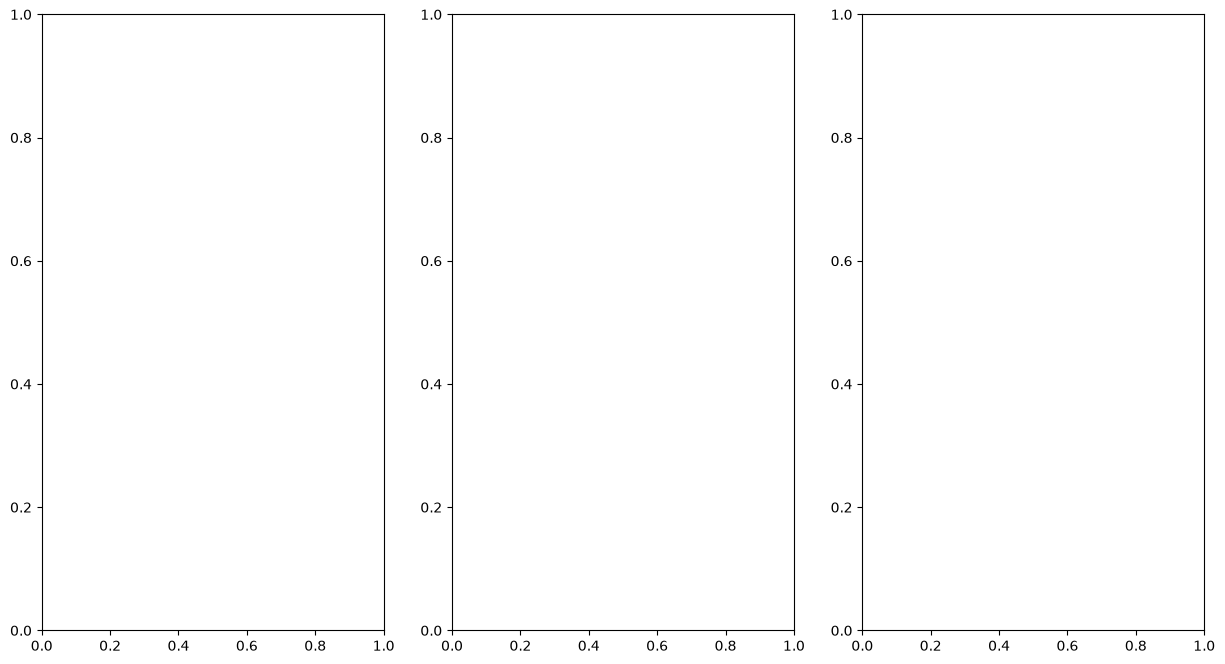

In [ ]:
case = ROOT / 'artifacts/physical_alignment/case_00'
fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for ax, name in zip(axes, ['input.png', 'rectified.png', 'overlay_expected_green_recovered_red.png']):
    ax.imshow(cv2.cvtColor(cv2.imread(str(case / name)), cv2.COLOR_BGR2RGB))
    ax.set_title(name); ax.axis('off')
plt.show()
metrics = json.loads((case / 'metrics.json').read_text())
{k:metrics[k] for k in ['mean_error_mm','max_error_mm','corner_errors_mm','under_0_5mm']}

## 2. Inspect your PDF or raster scan
Set a local path below. PDF_PAGE is zero-based. The plotted axes show source pixel coordinates after EXIF/PDF display rotation. Inspect actual paper edges, not text-box edges. Metadata is evidence, not a guarantee of original scan placement.

In [4]:
INPUT = None  # e.g. ROOT / 'data/my_scan.pdf' or Path(r'C:\path\scan.png')
PDF_PAGE = 0
if INPUT is not None:
    source = load_document(INPUT, page_index=PDF_PAGE, dpi=300)
    print(json.dumps(source.metadata, indent=2))
    plt.figure(figsize=(10, 12))
    plt.imshow(cv2.cvtColor(source.image, cv2.COLOR_BGR2RGB))
    plt.xlabel('Source X pixels'); plt.ylabel('Source Y pixels'); plt.grid(); plt.show()
else:
    print('Set INPUT to inspect your scan or PDF.')

Set INPUT to inspect your scan or PDF.


## 3. Compare a preview with explicit correction
Default remains unconfirmed. Choose `metadata` for faithful PDF page geometry or verified scanner DPI, `full_page` only when image edges are the complete paper edges, `corners` for borders/rotation/perspective, or `crop` for known DPI and measured crop offsets. Never enable nonuniform resizing to conceal cropping. See the guide for independent control-point measurements.

In [5]:
options = RegistrationOptions(mode='auto', confirmed=False)
# Example only, after measuring physical paper corners:
# options = RegistrationOptions(mode='corners', confirmed=True,
#     corners_px=((100,80),(900,90),(910,1200),(90,1210)))
if INPUT is not None:
    corrected, evidence = register_document(source, options=options)
    print(json.dumps(evidence['registration'], indent=2))
    for warning in evidence['warnings']: print(warning)
    plt.figure(figsize=(8, 10))
    plt.imshow(cv2.cvtColor(corrected, cv2.COLOR_BGR2RGB), extent=(0,210,297,0))
    plt.xlabel('Paper X mm'); plt.ylabel('Paper Y mm'); plt.grid(); plt.show()
    (ROOT / 'artifacts/physical_alignment/my_alignment.json').write_text(json.dumps(evidence, indent=2))

## 4. Prepare physical measurements (no automatic printing)
This creates an exact-size PDF and a blank measurement template, not measured results. Use the Canon procedure in the guide: independently verify scanner geometry, fit from uncorrected prints, then measure at least five separate corrected sheets. Do not overwrite completed measurements; choose a new session directory.

In [6]:
target_dir = ROOT / 'artifacts/canon2425i/new_session'
if (target_dir / 'measurements.json').exists():
    print('Session already exists; choose another directory to preserve measurements.')
else:
    print(write_target(target_dir / 'target.pdf', target_dir / 'measurements.json'))

Session already exists; choose another directory to preserve measurements.


Checking 1 file(s) from: C:\Users\saroy\OneDrive\Documents\Scans
Preview only - scale/origin unconfirmed | 0775_001.pdf | 3507 x 2481 px | physical_auto
  Preview only: physical scale and paper origin are not confirmed. Do not print this placement onto the original sheet.; Physical page is not portrait A4; export onto an A4 original is blocked.


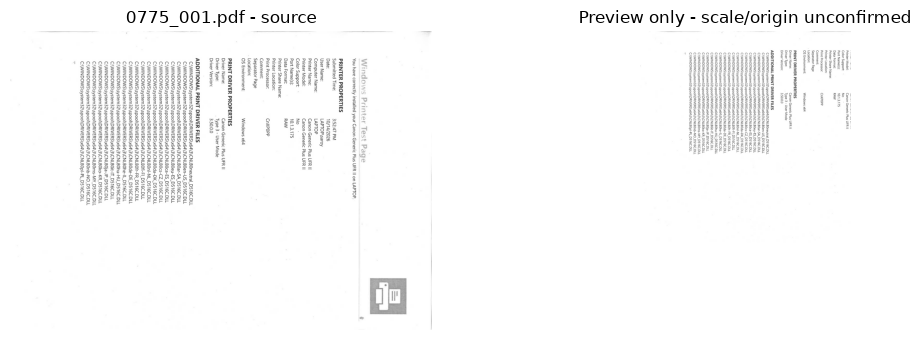

A preview fitting an A4 canvas does not confirm physical scale or page origin. Review the status before using an image for an overlay.


In [9]:
# Batch-check scans and PDFs. Add files under data/scanned_docs, or change SCAN_FOLDER.
from IPython.display import display, Markdown
from pathlib import Path
import matplotlib.pyplot as plt

SCAN_FOLDER = Path(r"C:\Users\saroy\OneDrive\Documents\Scans")
ONE_SCAN = None  # Or set to: SCAN_FOLDER / 'my_scan.pdf' to check just one file.
MAX_SCANS = 15  # Set to None to check every file in the folder.
PDF_PAGE_TO_CHECK = 0  # First page; change for another page in multi-page PDFs.
SUPPORTED = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp', '.pdf'}
if ONE_SCAN is not None:
    scan_files = [Path(ONE_SCAN)]
    if not scan_files[0].is_file():
        raise FileNotFoundError(f'Scan file not found: {scan_files[0]}')
else:
    scan_files = sorted(p for p in SCAN_FOLDER.rglob('*') if p.is_file() and p.suffix.lower() in SUPPORTED) if SCAN_FOLDER.is_dir() else []
if MAX_SCANS is not None:
    scan_files = scan_files[:MAX_SCANS]
print(f'Checking {len(scan_files)} file(s) from: {SCAN_FOLDER}')

scan_results = []
scan_previews = []
for scan_path in scan_files:
    try:
        scan_page = load_document(scan_path, page_index=PDF_PAGE_TO_CHECK, dpi=300)
        preview, evidence = register_document(scan_page, options=RegistrationOptions())
        registration = evidence['registration']
        physical_status = 'Registered under recorded assumptions' if registration['export_allowed'] else 'Preview only - scale/origin unconfirmed'
        scan_results.append({
            'file': scan_path.name,
            'source_pixels': f"{scan_page.metadata['source_size_px'][0]} x {scan_page.metadata['source_size_px'][1]}",
            'method': evidence.get('alignment_method', 'unknown'),
            'status': physical_status,
            'message': '; '.join(evidence.get('warnings', ())) or evidence.get('reason', ''),
        })
        scan_previews.append((scan_path, scan_page.image, preview, physical_status))
    except Exception as error:
        scan_results.append({'file': scan_path.name, 'source_pixels': '-', 'method': '-', 'status': 'Could not preview', 'message': str(error)})

if not scan_files:
    print('No supported scans found. Check SCAN_FOLDER or set ONE_SCAN to one image/PDF.')
for result in scan_results:
    print(f"{result['status']} | {result['file']} | {result['source_pixels']} px | {result['method']}")
    if result['message']:
        print(f"  {result['message']}")
# Show at most five documents per figure so previews stay easy to compare.
for start in range(0, len(scan_previews), 5):
    group = scan_previews[start:start + 5]
    fig, axes = plt.subplots(len(group), 2, figsize=(12, 3.5 * len(group)), squeeze=False)
    for row, (scan_path, source_image, preview_image, status) in enumerate(group):
        axes[row, 0].imshow(cv2.cvtColor(source_image, cv2.COLOR_BGR2RGB) if source_image.ndim == 3 else source_image, cmap=None if source_image.ndim == 3 else 'gray')
        axes[row, 0].set_title(f'{scan_path.name} - source'); axes[row, 0].axis('off')
        axes[row, 1].imshow(cv2.cvtColor(preview_image, cv2.COLOR_BGR2RGB) if preview_image.ndim == 3 else preview_image, cmap=None if preview_image.ndim == 3 else 'gray', extent=(0, 210, 297, 0))
        axes[row, 1].set_title(status); axes[row, 1].set_xlabel('A4 page width (mm)'); axes[row, 1].axis('off')
    plt.tight_layout(); plt.show()

print('A preview fitting an A4 canvas does not confirm physical scale or page origin. Review the status before using an image for an overlay.')